# Testing the other ways to read a drawing

Before settling on "locate each callout from the PDF, then read one crop at a time", the research tried the obvious options first. This notebook repeats those tests on the NIST drawings:

1. **What the PDF holds.** Is there text to copy out, and what are the annotations made of?
2. **OCR** (PP-OCRv5 through RapidOCR) on crops and on a whole page.
3. **Docling**, a document converter with a layout model and OCR.
4. **An image model** (Qwen3-VL 8B, 4-bit, through mlx-vlm, all local) on a whole page, and on small crops of single callouts.

The conclusions are in `research/drawing/README.md`; each section below ends with the point it supports. How the callout boxes are found is explained step by step in `callout_boxes.ipynb`; here the same code is used in one function, only to cut the crops.

Run it from `experiments/drawing/` (see the README there). The model cells download Qwen3-VL 8B (5.8 GB) on the first run. Timings in the saved outputs are from an Apple Silicon laptop.

In [1]:
from pathlib import Path
import collections, json, math, re, time
import numpy as np, pymupdf
import matplotlib.pyplot as plt

DRAWINGS = Path("../..") / "data" / "drawings"
PROMPTS = Path("prompts")
CROPS = Path("crops")              # images written by this notebook, git-ignored
CROPS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 110

def open_page(name, page_number=0):
    return pymupdf.open(DRAWINGS / f"nist_{name}.pdf")[page_number]

def render(page, dpi, clip=None):
    pixmap = page.get_pixmap(dpi=dpi, clip=clip)
    return np.frombuffer(pixmap.samples, np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)[:, :, :3]

def save_png(page, path, dpi, clip=None):
    page.get_pixmap(dpi=dpi, clip=clip).save(path)
    return str(path)

## 1. What the PDFs hold

For every page of the 11 drawings: the number of words in the text layer, the number of vector paths, and the number of raster images.

In [2]:
print(f"{'page':<28}{'size (pt)':>12}{'words':>7}{'paths':>7}{'images':>7}")
for pdf in sorted(DRAWINGS.glob("*.pdf")):
    for number, page in enumerate(pymupdf.open(pdf), start=1):
        size = f"{page.rect.width:.0f}x{page.rect.height:.0f}"
        print(f"{pdf.stem + ' p' + str(number):<28}{size:>12}{len(page.get_text('words')):>7}"
              f"{len(page.get_drawings()):>7}{len(page.get_images()):>7}")

page                           size (pt)  words  paths images
nist_ctc_01_asme1_rd p1          792x612     32   1797      0
nist_ctc_02_asme1_rc p1          792x612    122   1247      0
nist_ctc_02_asme1_rc p2          792x612     42   1339      0
nist_ctc_02_asme1_rc p3          792x612    160   1277      0


nist_ctc_03_asme1_rc p1          792x612     48   4049      0
nist_ctc_04_asme1_rd p1          792x612     56   1217      0
nist_ctc_05_asme1_rd p1          792x612     49   3069      0
nist_ctc_05_asme1_rd p2          792x612     49   1572      0
nist_ftc_06_asme1_rd p1          792x612    113   1264      0
nist_ftc_06_asme1_rd p2          792x612     24   1639      0
nist_ftc_06_asme1_rd p3          792x612     27    953      0
nist_ftc_07_asme1_rd p1          792x612    203    613      0


nist_ftc_07_asme1_rd p2          792x612    105    747      0
nist_ftc_07_asme1_rd p3          792x612     58    522      0
nist_ftc_07_asme1_rd p4          792x612     57    394      0
nist_ftc_08_asme1_rc p1          792x612    165   2591      0
nist_ftc_08_asme1_rc p2          792x612     25   2767      0
nist_ftc_08_asme1_rc p3          792x612     23   2467      0
nist_ftc_08_asme1_rc p4          792x612     25   3240      0


nist_ftc_09_asme1_rd p1          792x612    122   5319      0
nist_ftc_09_asme1_rd p2          792x612     25   5173      0
nist_ftc_09_asme1_rd p3          792x612     48   3345      0
nist_ftc_09_asme1_rd p4          792x612     45   5303      0
nist_ftc_10_asme1_rb p1          792x612    139   2954      0


nist_ftc_10_asme1_rb p2          792x612     29   2306      0
nist_ftc_10_asme1_rb p3          792x612     27   2273      0
nist_ftc_10_asme1_rb p4          792x612     23   1584      0
nist_ftc_10_asme1_rb p5          792x612     24    613      0
nist_ftc_11_asme1_rb p1          792x612    111   1922      0
nist_ftc_11_asme1_rb p2          792x612     23    818      0


Every page is vector only: thousands of paths and no images. The word counts are small. On CTC-01 the 32 words are only the title block:

In [3]:
page = open_page("ctc_01_asme1_rd")
print(page.get_text().strip().replace("\n", " | "))

PMI Complex Test Case 1 | Includes Atomic Test Cases - 1, 2, 3, 4, 7, 8, 17, 21, 33, 48 | NIST PMI Test Models - 2012 | Test Model 1 | Rev D | nist_ctc_01_asme1_rd


So the dimensions, tolerances and datum letters are not text; they are drawn as letter outlines. Counting the paths on that page by type and colour (`f` fill, `s` stroke, `fs` both) shows what they are made of:

In [4]:
def rounded_colour(colour):
    return None if colour is None else tuple(round(value, 2) for value in colour)

tally = collections.Counter(
    (path["type"], rounded_colour(path.get("color") or path.get("fill"))) for path in page.get_drawings())
for (kind, colour), count in tally.most_common(6):
    print(f"{count:6d}  type={kind:2s}  colour={colour}")

  1217  type=f   colour=(0.78, 0.69, 1.0)
   268  type=fs  colour=(0.0, 0.0, 1.0)
   167  type=s   colour=(0.0, 0.0, 1.0)
    92  type=s   colour=(0.0, 0.0, 0.0)
    44  type=f   colour=(0.0, 0.0, 1.0)
     3  type=fs  colour=(1.0, 0.25, 0.0)


Pure blue `(0, 0, 1)` is every annotation: letter shapes (`fs`), leaders and frame lines (`s`) and arrowheads (`f`). Black is the part outline and the pastel colours are its shaded faces. This is what the callout locator in `callout_boxes.ipynb` builds on.

**Point:** there is no text to copy out. The values have to be read from the picture, which is what the rest of this notebook tests.

## 2. The images the readers see

Each page is rendered at 150 dpi (for the image model on a whole page) and 300 dpi (for OCR, and for the crops). Then the callouts are located with the blue-path method, and two kinds of crop are cut at 300 dpi: `raw`, with an 8 pt margin, and `pad`, with 22 pt sideways and 16 pt up and down. The wider margin keeps the symbol cell of a tolerance frame in view.

In [5]:
BLUE = (0.0, 0.0, 1.0)

def find_callout_boxes(page):
    # Blue letter shapes and blue line segments, in displayed page coordinates
    rotation = page.rotation_matrix
    glyphs, lines = [], []
    for path in page.get_drawings():
        if BLUE not in (rounded_colour(path.get("color")), rounded_colour(path.get("fill"))):
            continue
        if path["type"] == "fs" and (path.get("width") or 0) < 0.1:
            glyphs.append(path["rect"] * rotation)
        elif path["type"] == "s":
            lines += [(item[1] * rotation, item[2] * rotation) for item in path["items"] if item[0] == "l"]
    letter_size = float(np.median([max(min(rect.width, rect.height), 1) for rect in glyphs]))

    # Join letters within two letter sizes of each other (union-find)
    parent = list(range(len(glyphs)))
    def root(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index
    margin = 2.0 * letter_size
    for first in range(len(glyphs)):
        grown = glyphs[first] + (-margin, -margin, margin, margin)
        for second in range(first + 1, len(glyphs)):
            if grown.intersects(glyphs[second]):
                parent[root(first)] = root(second)
    groups = collections.defaultdict(list)
    for index in range(len(glyphs)):
        groups[root(index)].append(index)

    # One box per group, with the frame lines whose two ends are both near it
    callouts = []
    for members in groups.values():
        box = pymupdf.Rect(glyphs[members[0]])
        for index in members[1:]:
            box |= glyphs[index]
        angle = 0.0
        if len(members) >= 3:
            centres = np.array([((glyphs[i].x0 + glyphs[i].x1) / 2, (glyphs[i].y0 + glyphs[i].y1) / 2) for i in members])
            _, _, directions = np.linalg.svd(centres - centres.mean(0), full_matrices=False)
            angle = (math.degrees(math.atan2(directions[0][1], directions[0][0])) + 90) % 180 - 90
        near = box + (-2.5 * letter_size, -2.5 * letter_size, 2.5 * letter_size, 2.5 * letter_size)
        for start, end in lines:
            if near.contains(start) and near.contains(end):
                box = box | start | end
        callouts.append({"box": box, "letters": len(members), "angle": angle})

    # Merge boxes that overlap and whose text runs the same way
    merged = True
    while merged:
        merged = False
        for first in range(len(callouts)):
            for second in range(first + 1, len(callouts)):
                a, b = callouts[first], callouts[second]
                if (a["box"] + (-letter_size, -letter_size, letter_size, letter_size)).intersects(b["box"]) \
                        and abs(a["angle"] - b["angle"]) < 20:
                    callouts[first] = {"box": a["box"] | b["box"], "letters": a["letters"] + b["letters"],
                                       "angle": a["angle"] if a["letters"] >= b["letters"] else b["angle"]}
                    del callouts[second]
                    merged = True
                    break
            if merged:
                break
    return sorted((callout["box"] for callout in callouts), key=lambda box: (box.y0, box.x0))

RAW_MARGIN = (-8, -8, 8, 8)
PAD_MARGIN = (-22, -16, 22, 16)

def cut_crop(name, box_number, margin):
    page = open_page(name)
    box = find_callout_boxes(page)[box_number]
    kind = "raw" if margin == RAW_MARGIN else "pad"
    return save_png(page, CROPS / f"{name}_{kind}{box_number:02d}.png", dpi=300, clip=box + margin)

for name in ["ctc_01_asme1_rd", "ctc_03_asme1_rc", "ftc_06_asme1_rd"]:
    print(f"{name}: {len(find_callout_boxes(open_page(name)))} callouts")

ctc_01_asme1_rd: 22 callouts


ctc_03_asme1_rc: 20 callouts
ftc_06_asme1_rd: 16 callouts


These are the eight crops used below: six tolerance frames and two plain dimensions, from three drawings.

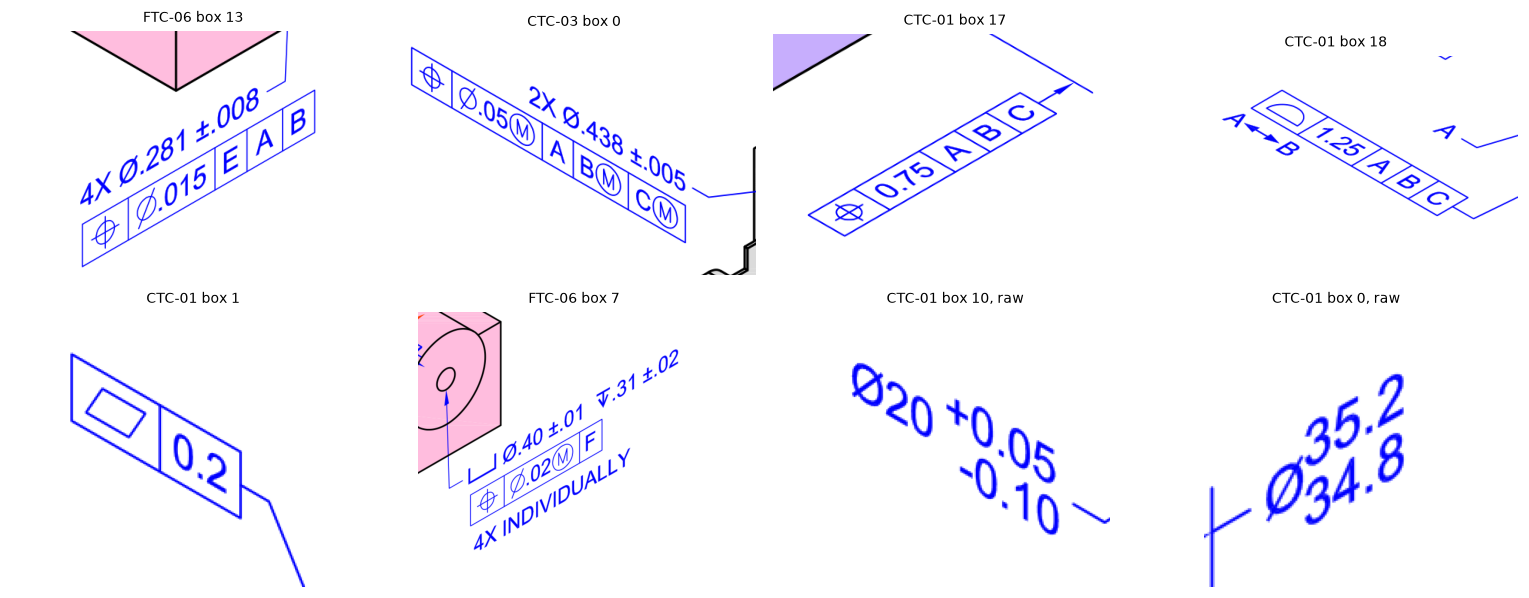

In [6]:
crops = {
    "FTC-06 box 13": cut_crop("ftc_06_asme1_rd", 13, PAD_MARGIN),
    "CTC-03 box 0": cut_crop("ctc_03_asme1_rc", 0, PAD_MARGIN),
    "CTC-01 box 17": cut_crop("ctc_01_asme1_rd", 17, PAD_MARGIN),
    "CTC-01 box 18": cut_crop("ctc_01_asme1_rd", 18, PAD_MARGIN),
    "CTC-01 box 1": cut_crop("ctc_01_asme1_rd", 1, PAD_MARGIN),
    "FTC-06 box 7": cut_crop("ftc_06_asme1_rd", 7, PAD_MARGIN),
    "CTC-01 box 10, raw": cut_crop("ctc_01_asme1_rd", 10, RAW_MARGIN),
    "CTC-01 box 0, raw": cut_crop("ctc_01_asme1_rd", 0, RAW_MARGIN),
}
figure, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for axis, (label, path) in zip(axes.flat, crops.items()):
    axis.imshow(plt.imread(path)); axis.set_title(label, fontsize=9); axis.axis("off")
plt.tight_layout(); plt.show()

pages = {name: {dpi: save_png(open_page(name), CROPS / f"{name}_p1_{dpi}.png", dpi) for dpi in (150, 300)}
         for name in ["ctc_01_asme1_rd", "ftc_06_asme1_rd"]}

## 3. OCR: RapidOCR

RapidOCR runs the PP-OCRv5 detection and recognition models on ONNX Runtime, on the CPU. First four CTC-01 crops, then whole pages at 300 dpi. The crops print `Ø35.2 / Ø34.8`, `Ø20 +0.05 -0.10`, a position frame `⌖ 0.75 A B C` and a profile frame `⌓ 1.25 A B C`.

In [7]:
from rapidocr import RapidOCR
ocr = RapidOCR()

def run_ocr(image_path):
    started = time.time()
    result = ocr(image_path)
    seconds = time.time() - started
    texts = list(result.txts) if result.txts else []
    scores = [round(float(score), 2) for score in (result.scores or [])]
    return list(zip(texts, scores)), seconds

for box_number in [0, 10, 17, 18]:
    lines, seconds = run_ocr(cut_crop("ctc_01_asme1_rd", box_number, RAW_MARGIN))
    print(f"CTC-01 box {box_number:2d}  {seconds:.2f}s  {lines}")

CTC-01 box  0  0.23s  [('35.2', 1.0), ('034.8', 0.81)]


CTC-01 box 10  0.14s  [('020 +0.05', 0.94), ('-0.10', 1.0)]


CTC-01 box 17  0.15s  [('0.75ABC', 1.0)]


CTC-01 box 18  0.20s  [('1.25A|B/C', 0.91), ('B', 1.0)]


In [8]:
for name, renders in pages.items():
    lines, seconds = run_ocr(renders[300])
    print(f"\n{name}, whole page at 300 dpi: {len(lines)} lines in {seconds:.1f}s")
    print(" | ".join(text for text, _ in lines))


ctc_01_asme1_rd, whole page at 300 dpi: 27 lines in 0.8s
NIST PMI Test Models - 2012 | Test Model 1 | 0.2 | A | 0.75ABC | z4 | 回 | 0.5A | Q | -034.8-35.2 | -025±0.15 | 020+0.05 | -0.10 | -0.2 | 020+0.10 | 1.5A | 0.05 | 60°±0.5° | 回 | /1.25ABC | A | 0.75ABC | nist_ctc_01_asme1_rd | -035 | PMI Complex Test Case 1 | Includes Atomic Test Cases - 1, 2, 3, 4, 7, 8, 17, 21, 33, 48 | Rev D



ftc_06_asme1_rd, whole page at 300 dpi: 49 lines in 1.3s
NIST PMI Test Models - 2014 | NOTES (UNLESS OTHERWISE SPECIFIED): | Feature and Specification Index | nist_ftc_06_asme1_rd_fsi.pdf | 1. CAD MODEL | REV.__IS REQUIRED | TO COMPLETE PRODUCT DEFINITION. | 2. DIRECTLY-TOLERANCED DIMENSIONS AND BASIC | DIMENSIONS DEFINED ON THE DRAWING TAKE | PRECEDENCE OVER DIMENSIONAL DATA | DEFINED BY THE MODEL. OBTAIN ALL OTHER | 2X CR.50 ±.02 | DIMENSIONAL DATA FROM THE MODEL. THE | 24XR.125±.020 | MODEL REPRESENTS BASIC DIMENSIONAL DATA | (SR.500) | UNLESS OTHERWISE SPECIFIED. | 2X S01.250 ±.008 | 3. APPLICABLE STANDARDS: | S0.025DBC | ASME Y14.41-2003 APPLIES TO DATASET. | ASME Y14.5M-1994 APPLIES TO DIMENSIONING | AND TOLERANCING. | 4. | .05 | APPLIES TO ALL | Z1 | D | UNTOLERANCED SURFACES. | Z1 | 5. UNITS: INCHES | 2X 0.562 ±.008 | Φ∅.015CAB | 10.40±.01 .31±.02 | .02F | 4X INDIVIDUALLY | 2XL/0.812 ±.020 .56±.02 | Φ∅.025CAB | 4X0.415±.008 | 0.625 ±.020 ￥.50 ±.02 | .025MABC | nist_ftc_06_asme

**Point:** the digits come out right, even rotated and even on a whole page in a second or two. But the diameter sign Ø often becomes the digit 0 (`034.8`, `020`), and every GD&T symbol is lost: the position and profile symbols are simply missing, so `0.75ABC` does not say what kind of tolerance it is. A text-only model after OCR cannot get back a symbol OCR never printed. OCR is useful as a cross-check on digits, not as the reader.

## 4. Docling

Docling converts a PDF into a structured document with a layout model. It runs once with its default OCR setting, and once with OCR forced over the full page.

In [9]:
from docling.document_converter import DocumentConverter, PdfFormatOption
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import PdfPipelineOptions, RapidOcrOptions

def run_docling(pdf, full_page_ocr):
    options = PdfPipelineOptions(do_ocr=True)
    if full_page_ocr:
        options.ocr_options = RapidOcrOptions(force_full_page_ocr=True)
    converter = DocumentConverter(format_options={InputFormat.PDF: PdfFormatOption(pipeline_options=options)})
    started = time.time()
    document = converter.convert(pdf).document
    kinds = collections.Counter(item.label.value for item, _ in document.iterate_items())
    print(f"full_page_ocr={full_page_ocr}  {time.time() - started:.1f}s  items={dict(kinds)}")
    print(document.export_to_markdown(), "\n")

for full_page_ocr in (False, True):
    run_docling(DRAWINGS / "nist_ctc_01_asme1_rd.pdf", full_page_ocr)

full_page_ocr=False  5.5s  items={'section_header': 1, 'picture': 1, 'text': 1}
## NIST PMI Test Models - 2012

<!-- image -->

nist\_ctc\_01\_asme1\_rd 



full_page_ocr=True  2.3s  items={'section_header': 1, 'picture': 1, 'text': 1}
## NIST PMI Test Models - 2012

<!-- image -->

nist\_ctc\_01\_asme1\_rd 



The first run includes loading Docling's models.

**Point:** Docling's layout model sees the whole drawing as one picture. It keeps the header and the file name and nothing else: every dimension is lost, with or without OCR. Docling is ruled out.

## 5. The image model: whole page versus crop

Qwen3-VL 8B, 4-bit, through mlx-vlm, with greedy decoding (temperature 0). The prompts are in `prompts/`:

- `page.txt` asks for every annotation on a full sheet as JSON.
- `crop_b_glossary.txt` asks for every line and every frame cell of one crop, and names what each GD&T symbol looks like.

In [10]:
from mlx_vlm import load, generate
from mlx_vlm.prompt_utils import apply_chat_template

MODEL_ID = "mlx-community/Qwen3-VL-8B-Instruct-4bit"
started = time.time()
model, processor = load(MODEL_ID)
print(f"loaded {MODEL_ID} in {time.time() - started:.1f}s")

def ask_model(prompt_file, image_path, max_tokens):
    prompt = apply_chat_template(processor, model.config, (PROMPTS / prompt_file).read_text(), num_images=1)
    started = time.time()
    output = generate(model, processor, prompt, [image_path], max_tokens=max_tokens, temperature=0.0, verbose=False)
    text = output.text if hasattr(output, "text") else output
    return text.strip(), time.time() - started

def parse_json(text):
    # The model sometimes wraps its answer in a ```json fence
    try:
        return json.loads(re.sub(r"^```(json)?|```$", "", text.strip()).strip())
    except json.JSONDecodeError:
        return None

loaded mlx-community/Qwen3-VL-8B-Instruct-4bit in 3.5s


### Whole page

CTC-01 is a sparse sheet; FTC-06 is a dense one. Both at 150 dpi.

In [11]:
for name, max_tokens in [("ctc_01_asme1_rd", 2500), ("ftc_06_asme1_rd", 3000)]:
    text, seconds = ask_model("page.txt", pages[name][150], max_tokens)
    answer = parse_json(text)
    print(f"\n{name}: {seconds:.0f}s")
    if answer is None:
        entries = re.findall(r'"text":\s*"([^"]*)"', text)
        repeats = collections.Counter(entries).most_common(1)[0]
        print(f"no complete JSON: {len(entries)} entries before the token limit; "
              f"'{repeats[0]}' appears {repeats[1]} times")
        print(" | ".join(entries[:30]))
    else:
        for entry in answer["annotations"]:
            meaning = f"  ({entry['meaning']})" if entry["kind"] == "feature control frame" else ""
            print(f"  {entry['kind']:<22} {entry['text']}{meaning}")


ctc_01_asme1_rd: 52s
  dimension              0.2
  dimension              Ø35.2
  dimension              Ø34.8
  dimension              Ø20 +0.05 -0.10
  dimension              Ø20 +0.10 -0.05
  dimension              Ø35 0 -0.2
  dimension              Ø25 ±0.15
  dimension              Ø34.8 - 35.2
  dimension              1.5
  dimension              60° ±0.5°
  dimension              Ø35 +0.2 0
  feature control frame  0.75 A B C  (Perpendicularity tolerance of 0.75 with datums A, B, and C.)
  feature control frame  0.75 A B C  (Perpendicularity tolerance of 0.75 with datums A, B, and C.)
  feature control frame  1.25 A B C  (Perpendicularity tolerance of 1.25 with datums A, B, and C.)
  feature control frame  0.5 A  (Perpendicularity tolerance of 0.5 with datum A.)
  datum label            A
  datum label            B
  datum label            C
  note                   NIST PMI Test Models - 2012
  note                   Test Model 1
  note                   PMI Complex Test Cas


ftc_06_asme1_rd: 113s
no complete JSON: 59 entries before the token limit; 'Ø.025 A B C' appears 38 times
2X CR.50 ±.02 | 24X R.125 ±.020 | 2X SØ1.250 ±.008 | SØ.025 D B C | Ø.02 A B C | Ø.01 | 2X Ø.562 ±.008 | Ø.015 C A B | 2X L Ø.812 ±.020 | Ø.56 ±.02 | Ø.025(M) C A B | 4X Ø.415 ±.008 | Ø.825 ±.020 | Ø.50 ±.02 | Ø.025 A B C | L Ø.40 ±.01 | Ø.31 ±.02 | Ø.02(M) F | 4X INDIVIDUALLY | 4X Ø.281 ±.008 | Ø.015 E A B | Ø.01 | Ø.025 A B C | Ø.025 A B C | Ø.025 A B C | Ø.025 A B C | Ø.025 A B C | Ø.025 A B C | Ø.025 A B C | Ø.025 A B C


On CTC-01 the numbers are mostly right, but there is no GD&T symbol anywhere: the frames come out as `0.75 A B C`, and the model guesses "perpendicularity" for all of them, although two are position frames and one is profile. On FTC-06 it reads `Ø.825` where the drawing says `Ø.625`, then repeats one entry until it runs out of tokens. A page takes one to two minutes.

### One crop at a time

The same model on the eight crops, with the symbol-naming prompt.

In [12]:
for label, path in crops.items():
    text, seconds = ask_model("crop_b_glossary.txt", path, 700)
    answer = parse_json(text) or {"lines": [text], "feature_control_frames": []}
    frames = "; ".join(f"{frame['symbol_name']} {frame['tolerance']} {' '.join(frame['modifiers'])} | {' '.join(frame['datums'])}"
                       for frame in answer["feature_control_frames"])
    print(f"{label:<20} {seconds:4.1f}s  lines={answer['lines']}")
    if frames:
        print(f"{'':<27}frames: {frames}")

FTC-06 box 13         5.6s  lines=['4X Ø.281 ±.008', 'Ø.015', 'E', 'A', 'B']
                           frames: position Ø.015  | E A B


CTC-03 box 0          4.9s  lines=['2X Ø.438 ±.005']
                           frames: position Ø.05M  | A B C


CTC-01 box 17         4.8s  lines=['0.75', 'A', 'B', 'C']
                           frames: position 0.75  | A B C


CTC-01 box 18         5.0s  lines=['1.25', 'A', 'B', 'C']
                           frames: profile of a surface 1.25  | A B C


CTC-01 box 1          3.7s  lines=['0.2']
                           frames: flatness 0.2  | 


FTC-06 box 7          6.7s  lines=['Ø.40 ±.01', '√.31 ±.02', 'Ø.02Ⓜ', 'F', '4X INDIVIDUALLY']
                           frames: position Ø.02 M | F


CTC-01 box 10, raw    2.8s  lines=['Ø20 +0.05', '-0.10']


CTC-01 box 0, raw     2.8s  lines=['Ø35.2', 'Ø34.8']


**Point:** on a crop, the model names the characteristic symbol of every frame (position, profile of a surface, flatness) and reads the datum letters, in a few seconds per crop. It still misses rarer marks: the circled M on datums B and C of the CTC-03 frame, and the counterbore and depth symbols on FTC-06 box 7. The same model on the whole page reads most numbers but no symbols, and breaks down on a dense sheet. That is why the recommendation is to locate the callouts from the PDF and read one crop at a time, with the whole page kept as the baseline to beat.

The wider comparison (Qwen3-VL 4B, MechVL-4B, OCR text as a prompt hint, scoring against 46 checks) is summarised in `research/drawing/README.md`.